# Applied Data Science – Vorlesung 1 (erweiterte Version)
### Dieselben Themen – mehr Rechenbeispiele, erklärter Python-Code und Visualisierungen

Diese Version baut **ausschließlich** die Themen des Ausgangsnotebooks aus:

1. Listen/Vektoren, Mittelwert, Varianz (mit **$n$** im Nenner), Kovarianz, Korrelation und Standardisierung.
2. Lineare Regression mit **einem** Merkmal: $\hat y=a+bx$, mit $b=\mathrm{Cov}(x,y)/\mathrm{Var}(x)$ und $a=\bar y-b\bar x$.
3. **MSE** als Fehler- und Zielfunktion.
4. **Gradient Descent** für die 1D-Regression.
5. Mehrere Merkmale, **Designmatrix** und der eingebaute **Least-Squares-Solver**.
6. **Train/Test-Aufteilung**, Standardisierung anhand der Trainingsdaten und **Test-MSE**.

**Bibliotheken:** NumPy für sämtliche Berechnungen; Matplotlib ausschließlich zur Darstellung. Alle Zufallsbeispiele besitzen feste Seeds und sind reproduzierbar.

**So verwenden:** Zellen der Reihe nach ausführen (`Run All`). Die Diagramme werden direkt unter den jeweiligen Code-Zellen angezeigt.

In [1]:
# 0) Vorbereitung: ausschließlich NumPy und Matplotlib
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams.update({
    "figure.figsize": (8.6, 4.6),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
})

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 2.0.2
Matplotlib: 3.10.8


## 0. Listen/Vektoren und beschreibende Statistik (A1)

Eine Liste von Messwerten wird im Notebook als **NumPy-Vektor** gespeichert. Für $v=(v_1,\ldots,v_n)$ verwenden wir konsequent die Definitionen aus dem Ausgangsnotebook:

$$
\bar v=\frac1n\sum_{i=1}^n v_i,\qquad
\operatorname{Var}_n(v)=\frac1n\sum_{i=1}^n(v_i-\bar v)^2,\qquad
\operatorname{Std}_n(v)=\sqrt{\operatorname{Var}_n(v)}.
$$

Für gleich lange Vektoren $x$ und $y$ gilt:

$$
\operatorname{Cov}_n(x,y)=\frac1n\sum_i(x_i-\bar x)(y_i-\bar y),\qquad
\operatorname{Corr}(x,y)=\frac{\operatorname{Cov}_n(x,y)}{\operatorname{Std}_n(x)\operatorname{Std}_n(y)}.
$$

**Wichtig:** Die Varianz und Kovarianz verwenden hier **$n$ (nicht $n-1$)**. Ist eine Standardabweichung null, ist die mathematische Korrelation nicht definiert; der einfache Helfer des Originalskripts liefert dafür konventionsgemäß `0.0` zurück.

In [2]:
# 0.1) Die Statistik-Funktionen aus dem Original, etwas robuster dokumentiert

def mean(v):
    """Arithmetischer Mittelwert eines nichtleeren 1D-Vektors."""
    v = np.asarray(v, dtype=float)
    return np.sum(v) / v.shape[0]


def var_n(v):
    """Varianz mit n im Nenner."""
    v = np.asarray(v, dtype=float)
    m = mean(v)
    return np.sum((v - m) ** 2) / v.shape[0]


def std_n(v):
    return np.sqrt(var_n(v))


def cov_n(x, y):
    """Kovarianz mit n im Nenner; x und y sind gleich lang."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    return np.sum((x - mean(x)) * (y - mean(y))) / x.shape[0]


def corr_xy(x, y):
    sx, sy = std_n(x), std_n(y)
    if sx == 0 or sy == 0:
        return 0.0  # Originalkonvention; mathematisch wäre Corr undefiniert.
    return cov_n(x, y) / (sx * sy)


def standardize(x):
    """z-Werte, Mittelwert und Standardabweichung für einen 1D-Vektor."""
    x = np.asarray(x, dtype=float)
    mu, sd = mean(x), std_n(x)
    scale = sd if sd > 0 else 1.0
    return (x - mu) / scale, mu, sd


def mse(y_true, y_pred):
    """Mean Squared Error (mittlerer quadratischer Fehler)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)

### Beispiel 0a: Von einer Liste zur Mittelwert- und Varianzrechnung

Mit nur fünf Werten lassen sich die Zwischenschritte direkt kontrollieren. Die Abstände zum Mittelwert sind positiv oder negativ; durch das **Quadrieren** werden daraus nichtnegative Beiträge zur Varianz.

In [3]:
werte = np.array([2, 4, 4, 6, 9], dtype=float)
m = mean(werte)
abweichungen = werte - m
quadrate = abweichungen ** 2

print("Werte:                   ", werte)
print("Mittelwert:              ", round(m, 3))
print("Abweichungen:            ", np.round(abweichungen, 3))
print("Quadrierte Abweichungen: ", np.round(quadrate, 3))
print("Varianz (mit n):         ", round(var_n(werte), 3))
print("Standardabweichung:      ", round(std_n(werte), 3))
assert np.isclose(np.sum(abweichungen), 0)

Werte:                    [2. 4. 4. 6. 9.]
Mittelwert:               5.0
Abweichungen:             [-3. -1. -1.  1.  4.]
Quadrierte Abweichungen:  [ 9.  1.  1.  1. 16.]
Varianz (mit n):          5.6
Standardabweichung:       2.366


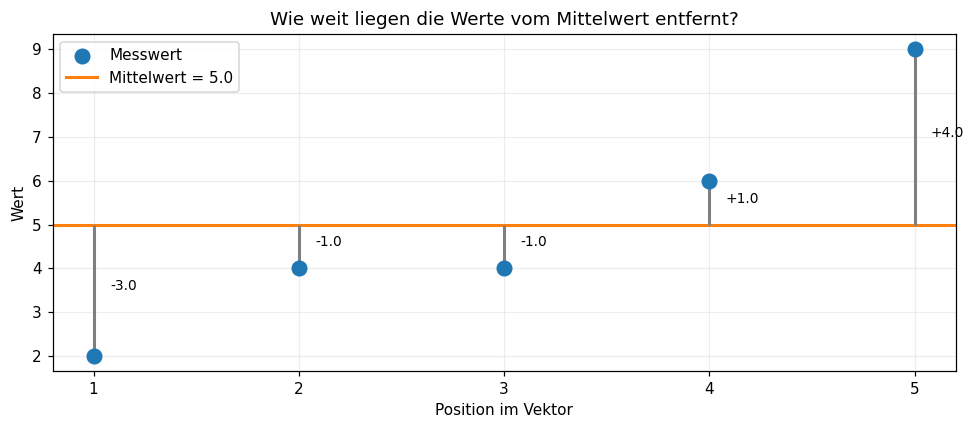

In [4]:
# Visualisierung 1: Punkte, Mittelwert und Abweichungen
fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(1, len(werte) + 1)
ax.scatter(idx, werte, s=90, color="tab:blue", zorder=3, label="Messwert")
ax.axhline(m, color="tab:orange", lw=2, label=f"Mittelwert = {m:.1f}")
for k, (i, v) in enumerate(zip(idx, werte)):
    ax.vlines(i, min(v, m), max(v, m), color="tab:gray", lw=2)
    ax.text(i + 0.08, (v + m) / 2, f"{v - m:+.1f}", fontsize=9)
ax.set(xticks=idx, xlabel="Position im Vektor", ylabel="Wert",
       title="Wie weit liegen die Werte vom Mittelwert entfernt?")
ax.legend()
plt.tight_layout()
plt.show()

### Beispiel 0b: Kovarianz und Korrelation bei positivem, negativem und schwachem Zusammenhang

- Bei gemeinsam steigenden Werten ist die Kovarianz typischerweise **positiv**.
- Steigt der eine Vektor und fällt der andere, ist sie typischerweise **negativ**.
- Die **Korrelation** teilt durch beide Standardabweichungen und liegt dadurch zwischen $-1$ und $1$.

Wir vergleichen drei unterschiedliche Paare, ohne den Themenbereich der Kovarianz/Korrelation zu verlassen.

In [5]:
zufall_statistik = np.random.default_rng(12)
x_corr = np.linspace(0, 10, 60)
y_positiv = 1.8 * x_corr + zufall_statistik.normal(0, 2, x_corr.size)
y_negativ = -1.5 * x_corr + zufall_statistik.normal(0, 2, x_corr.size)
y_schwach = zufall_statistik.normal(0, 3, x_corr.size)

for bezeichnung, yy in [
    ("Positiver Zusammenhang", y_positiv),
    ("Negativer Zusammenhang", y_negativ),
    ("Schwacher Zusammenhang", y_schwach),
]:
    print(f"{bezeichnung:26s} | Cov = {cov_n(x_corr, yy):7.3f}"
          f" | Corr = {corr_xy(x_corr, yy):6.3f}")

Positiver Zusammenhang     | Cov =  16.489 | Corr =  0.951
Negativer Zusammenhang     | Cov = -12.184 | Corr = -0.917
Schwacher Zusammenhang     | Cov =  -0.083 | Corr = -0.009


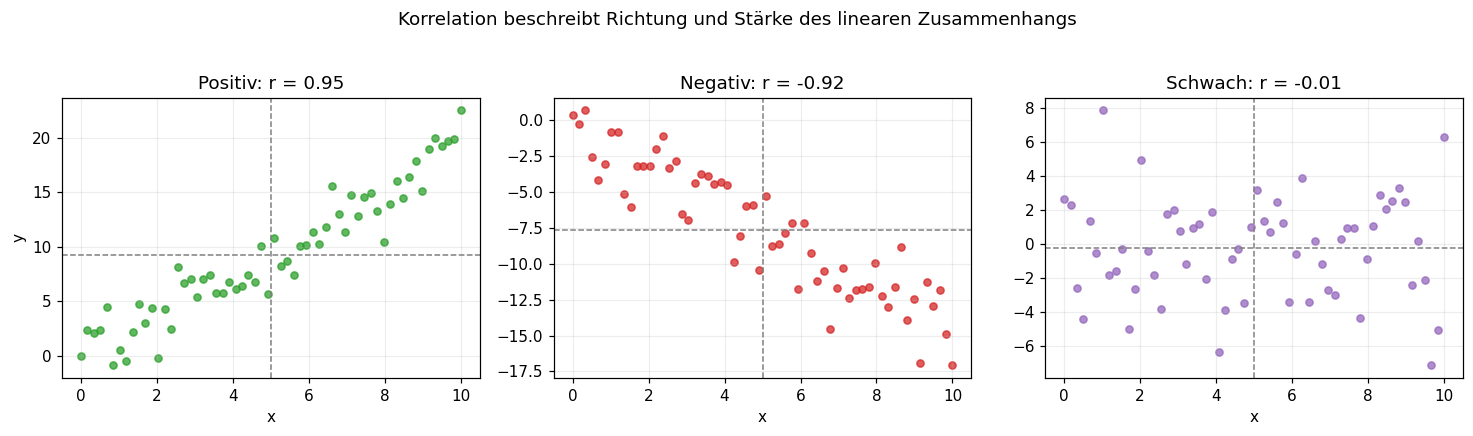

In [6]:
# Visualisierung 2: Drei Scatterplots mit Korrelationswerten
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharex=True)
for ax, yy, name, farbe in zip(
    axes,
    [y_positiv, y_negativ, y_schwach],
    ["Positiv", "Negativ", "Schwach"],
    ["tab:green", "tab:red", "tab:purple"],
):
    ax.scatter(x_corr, yy, alpha=0.75, s=22, color=farbe)
    ax.axvline(mean(x_corr), color="gray", ls="--", lw=1)
    ax.axhline(mean(yy), color="gray", ls="--", lw=1)
    ax.set(title=f"{name}: r = {corr_xy(x_corr, yy):.2f}", xlabel="x")
axes[0].set_ylabel("y")
fig.suptitle("Korrelation beschreibt Richtung und Stärke des linearen Zusammenhangs", y=1.03)
plt.tight_layout()
plt.show()

### Beispiel 0c: Standardisierung eines Vektors

Die Standardisierung verschiebt den Mittelwert auf **0** und skaliert (bei nichtkonstanten Werten) die Standardabweichung auf **1**:

$$z_i=\frac{x_i-\bar x}{\operatorname{Std}_n(x)}.$$

Dieselbe Transformation wird im Gradient Descent und beim Train/Test-Beispiel erneut verwendet.

In [7]:
x_skala = np.array([30, 40, 50, 60, 70], dtype=float)
z_skala, x_mu_skala, x_sd_skala = standardize(x_skala)

print("Original:", x_skala)
print("z-Werte: ", np.round(z_skala, 3))
print(f"Original: Mittelwert={mean(x_skala):.3f}, Std={std_n(x_skala):.3f}")
print(f"z-Werte:  Mittelwert={mean(z_skala):.3f}, Std={std_n(z_skala):.3f}")
assert np.isclose(mean(z_skala), 0.0)
assert np.isclose(std_n(z_skala), 1.0)

Original: [30. 40. 50. 60. 70.]
z-Werte:  [-1.414 -0.707  0.     0.707  1.414]
Original: Mittelwert=50.000, Std=14.142
z-Werte:  Mittelwert=0.000, Std=1.000


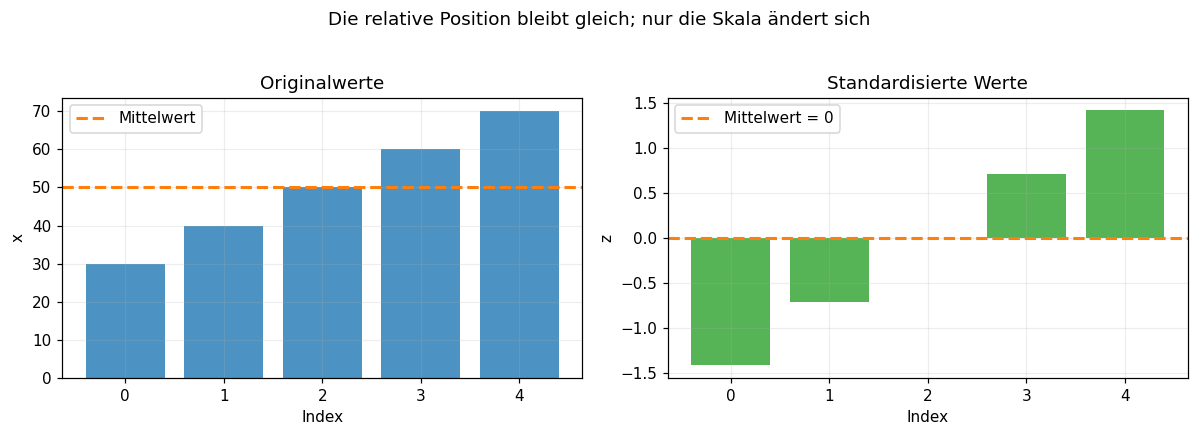

In [8]:
# Visualisierung 3: Derselbe Vektor auf zwei Skalen
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
positions = np.arange(x_skala.size)
axes[0].bar(positions, x_skala, color="tab:blue", alpha=0.8)
axes[0].axhline(x_mu_skala, ls="--", lw=2, color="tab:orange", label="Mittelwert")
axes[0].set(title="Originalwerte", xlabel="Index", ylabel="x", xticks=positions)
axes[0].legend()
axes[1].bar(positions, z_skala, color="tab:green", alpha=0.8)
axes[1].axhline(0, ls="--", lw=2, color="tab:orange", label="Mittelwert = 0")
axes[1].set(title="Standardisierte Werte", xlabel="Index", ylabel="z", xticks=positions)
axes[1].legend()
fig.suptitle("Die relative Position bleibt gleich; nur die Skala ändert sich", y=1.03)
plt.tight_layout()
plt.show()

## 1. 1D-Regressionsgerade mit Mittelwert, Kovarianz und Varianz (A7)

Die vorhergesagten Werte heißen $\hat y_i=a+bx_i$. Die Gerade, die den MSE minimiert, erhält man bei $\operatorname{Var}_n(x)>0$ direkt aus:

$$ b=\frac{\operatorname{Cov}_n(x,y)}{\operatorname{Var}_n(x)},\qquad a=\bar y-b\bar x.$$

Wir übernehmen **genau die fünf Datenpunkte** des Ausgangsnotebooks. `y` ist dort in Einheiten von **100 €** angegeben.

In [9]:
# Originalbeispiel: x und y unverändert
x = np.array([30, 40, 50, 60, 70], dtype=float)
y = np.array([2, 3, 5, 4, 6], dtype=float)  # y in 100 €

xb, yb = mean(x), mean(y)
b = cov_n(x, y) / var_n(x)
a = yb - b * xb
y_hat = a + b * x

print(f"x̄ = {xb:.3f}; ȳ = {yb:.3f}")
print(f"Var_n(x) = {var_n(x):.3f}; Cov_n(x,y) = {cov_n(x,y):.3f}")
print(f"Regressionsgerade: ŷ = {a:.3f} + {b:.3f} · x")
print(f"MSE = {mse(y, y_hat):.4f} (in quadrierten Einheiten von 100 €)")
print("\n   x    y     ŷ   y-ŷ")
for xi, yi, yhi in zip(x, y, y_hat):
    print(f"{xi:4.0f} {yi:4.1f} {yhi:5.2f} {yi-yhi:+5.2f}")
assert np.isclose(a, -0.5) and np.isclose(b, 0.09)
assert np.isclose(mse(y, y_hat), 0.38)

x̄ = 50.000; ȳ = 4.000
Var_n(x) = 200.000; Cov_n(x,y) = 18.000
Regressionsgerade: ŷ = -0.500 + 0.090 · x
MSE = 0.3800 (in quadrierten Einheiten von 100 €)

   x    y     ŷ   y-ŷ
  30  2.0  2.20 -0.20
  40  3.0  3.10 -0.10
  50  5.0  4.00 +1.00
  60  4.0  4.90 -0.90
  70  6.0  5.80 +0.20


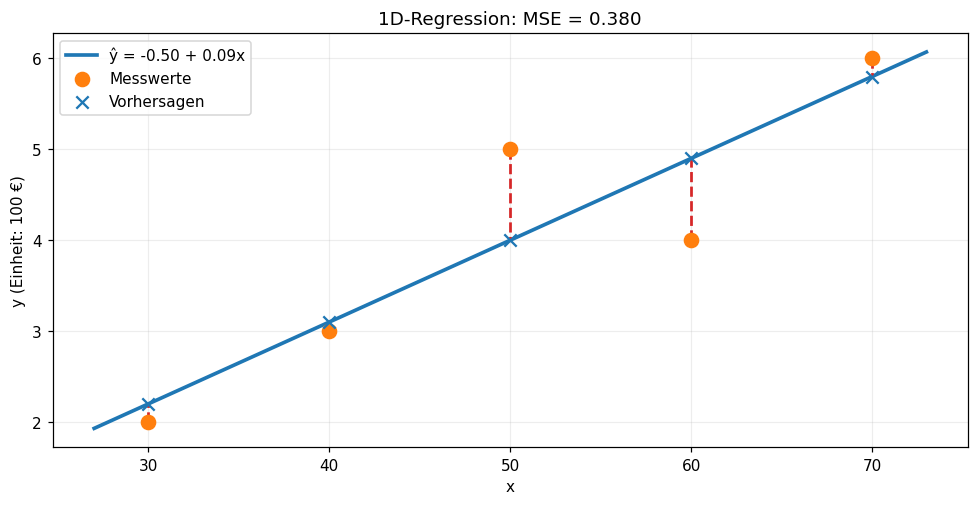

In [10]:
# Visualisierung 4: Beobachtungen, Gerade und die Abstände y - ŷ
fig, ax = plt.subplots(figsize=(9, 4.7))
x_line = np.linspace(x.min() - 3, x.max() + 3, 150)
ax.plot(x_line, a + b * x_line, color="tab:blue", lw=2.4,
        label=f"ŷ = {a:.2f} + {b:.2f}x")
ax.scatter(x, y, color="tab:orange", s=85, zorder=3, label="Messwerte")
ax.scatter(x, y_hat, marker="x", color="tab:blue", s=65, zorder=3, label="Vorhersagen")
for xi, yi, yhi in zip(x, y, y_hat):
    ax.plot([xi, xi], [yi, yhi], color="tab:red", ls="--", lw=1.8)
ax.set(title=f"1D-Regression: MSE = {mse(y, y_hat):.3f}",
       xlabel="x", ylabel="y (Einheit: 100 €)")
ax.legend()
plt.tight_layout()
plt.show()

### Zweites 1D-Beispiel: Mehr Datenpunkte, dieselbe Formel

Wir erzeugen zusätzliche Beobachtungen, deren Werte um eine Gerade streuen. Das zugrunde liegende Thema bleibt unverändert: **1D-Regression mit $a$ und $b$**.

In [11]:
def fit_regression_1d(x_v, y_v):
    """Berechnet a und b mit Cov/Var und a = ȳ - b x̄."""
    if np.isclose(var_n(x_v), 0):
        raise ValueError("Für eine Regressionsgerade muss Var(x) > 0 gelten.")
    steigung = cov_n(x_v, y_v) / var_n(x_v)
    abschnitt = mean(y_v) - steigung * mean(x_v)
    return abschnitt, steigung

rng_1d = np.random.default_rng(7)
x_weiter = np.linspace(10, 35, 25)
y_weiter = 1.2 + 0.16 * x_weiter + rng_1d.normal(0, 0.45, size=x_weiter.size)
a_weiter, b_weiter = fit_regression_1d(x_weiter, y_weiter)

print(f"Fünf Werte:       a={a:.3f}, b={b:.3f}, MSE={mse(y, y_hat):.3f}")
print(f"25 weitere Werte: a={a_weiter:.3f}, b={b_weiter:.3f}, "
      f"MSE={mse(y_weiter, a_weiter + b_weiter*x_weiter):.3f}")

Fünf Werte:       a=-0.500, b=0.090, MSE=0.380
25 weitere Werte: a=1.319, b=0.147, MSE=0.115


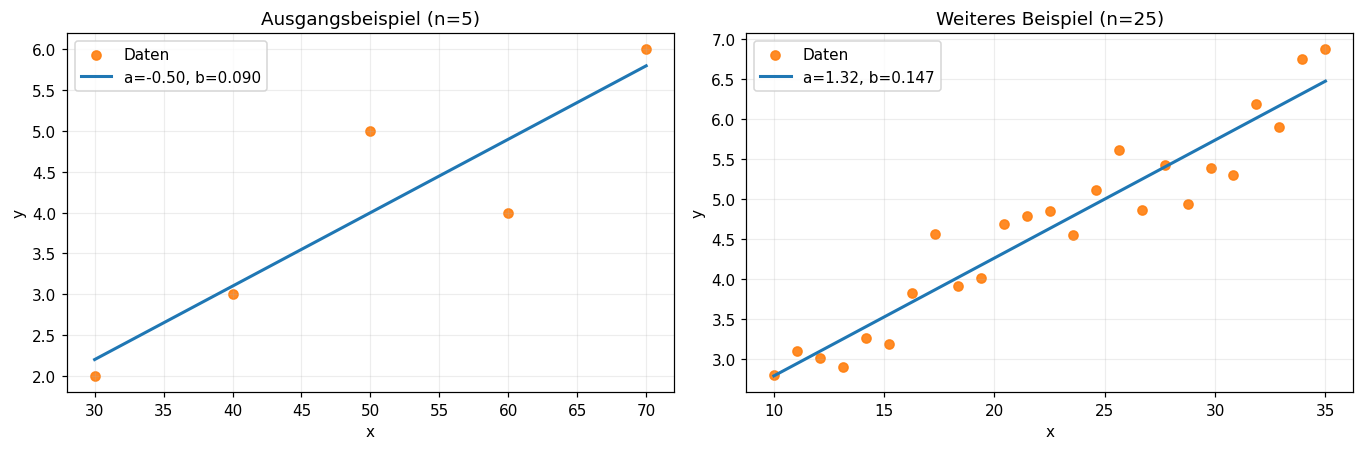

In [12]:
# Visualisierung 5: Zwei voneinander unabhängige Regressionsbeispiele
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
for ax, xx, yy, aa, bb, titel in [
    (axes[0], x, y, a, b, "Ausgangsbeispiel (n=5)"),
    (axes[1], x_weiter, y_weiter, a_weiter, b_weiter, "Weiteres Beispiel (n=25)"),
]:
    xx_plot = np.linspace(xx.min(), xx.max(), 120)
    ax.scatter(xx, yy, color="tab:orange", alpha=0.9, label="Daten")
    ax.plot(xx_plot, aa + bb * xx_plot, color="tab:blue", lw=2,
            label=f"a={aa:.2f}, b={bb:.3f}")
    ax.set(xlabel="x", ylabel="y", title=titel)
    ax.legend()
plt.tight_layout()
plt.show()

## 2. MSE als Zielfunktion

Für eine beliebige Gerade $\hat y_i=a+bx_i$ misst der **Mean Squared Error** den durchschnittlichen quadrierten Vorhersagefehler:

$$ \mathrm{MSE}(a,b)=\frac1n\sum_{i=1}^n\left(y_i-(a+bx_i)\right)^2. $$

Wir variieren $a$ und $b$ bei denselben Daten, um zu sehen, was „**MSE minimieren**“ bedeutet. Es kommen **keine weiteren Fehlermetriken** hinzu.

In [13]:
# Beispiel: Drei Geraden. Zum fairen Vergleich erhält jede Steigung den
# zugehörigen Achsenabschnitt a = ȳ - b·x̄.
steigungen = [0.04, b, 0.14]
namen = ["zu flach", "MSE-minimal", "zu steil"]
farben = ["tab:purple", "tab:green", "tab:red"]
modelle = [(yb - bi * xb, bi) for bi in steigungen]
modell_mse = [mse(y, ai + bi * x) for ai, bi in modelle]

for name, (ai, bi), fehler in zip(namen, modelle, modell_mse):
    print(f"{name:12s}: a={ai:+.2f}, b={bi:.2f}, MSE={fehler:.3f}")

zu flach    : a=+2.00, b=0.04, MSE=0.880
MSE-minimal : a=-0.50, b=0.09, MSE=0.380
zu steil    : a=-3.00, b=0.14, MSE=0.880


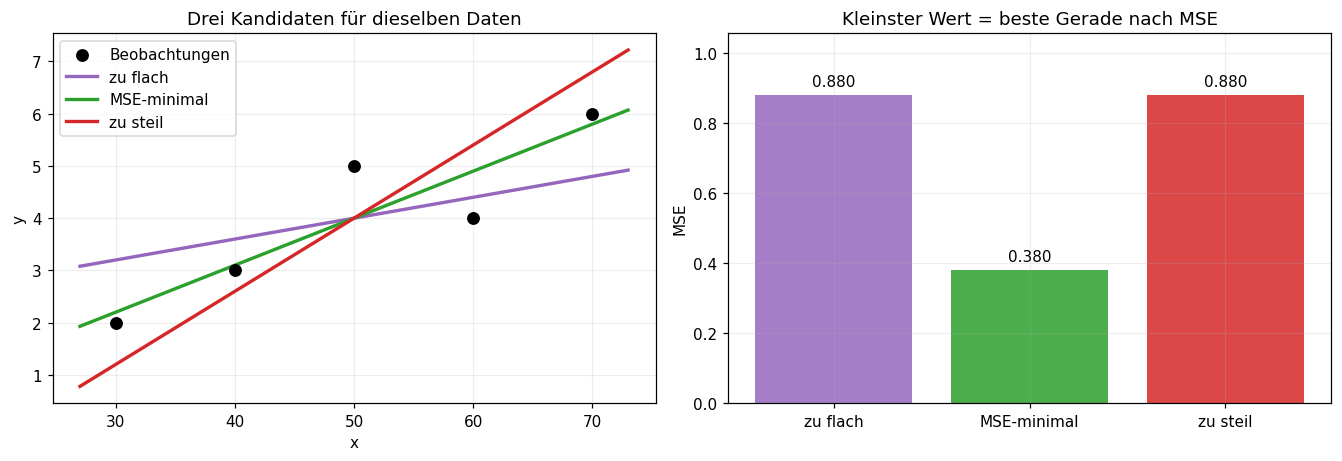

In [14]:
# Visualisierung 6: Unterschiedliche Geraden und ihre MSE-Werte
fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.3))
axes[0].scatter(x, y, color="black", s=55, zorder=4, label="Beobachtungen")
for name, (ai, bi), farbe in zip(namen, modelle, farben):
    axes[0].plot(x_line, ai + bi * x_line, lw=2.2, color=farbe, label=name)
axes[0].set(xlabel="x", ylabel="y", title="Drei Kandidaten für dieselben Daten")
axes[0].legend()
axes[1].bar(namen, modell_mse, color=farben, alpha=0.85)
axes[1].set(ylabel="MSE", title="Kleinster Wert = beste Gerade nach MSE")
for index, val in enumerate(modell_mse):
    axes[1].text(index, val + 0.025, f"{val:.3f}", ha="center")
axes[1].set_ylim(0, max(modell_mse) * 1.20)
plt.tight_layout()
plt.show()

### MSE in Abhängigkeit von den Regressionsparametern

Zuerst ändern wir nur die Steigung $b$ und passen dazu jeweils $a=\bar y-b\bar x$ an. Anschließend betrachten wir beide Parameter gleichzeitig. Der Tiefpunkt liegt beim zuvor berechneten Wertepaar $(a,b)$.

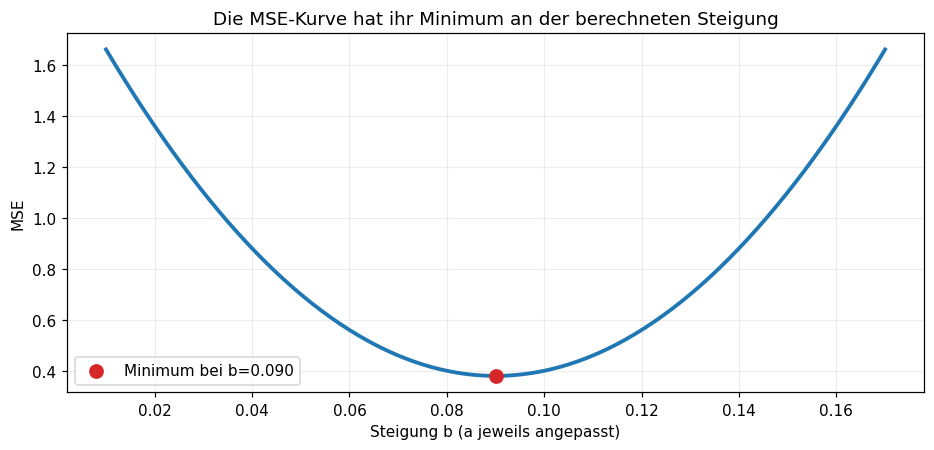

In [15]:
# Visualisierung 7: MSE-Kurve als Funktion der Steigung b
b_werte = np.linspace(0.01, 0.17, 250)
mse_werte = np.array([
    mse(y, (yb - bi * xb) + bi * x) for bi in b_werte
])

fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.plot(b_werte, mse_werte, lw=2.5, color="tab:blue")
ax.scatter([b], [mse(y, y_hat)], color="tab:red", s=75, zorder=4,
           label=f"Minimum bei b={b:.3f}")
ax.set(xlabel="Steigung b (a jeweils angepasst)", ylabel="MSE",
       title="Die MSE-Kurve hat ihr Minimum an der berechneten Steigung")
ax.legend()
plt.tight_layout()
plt.show()

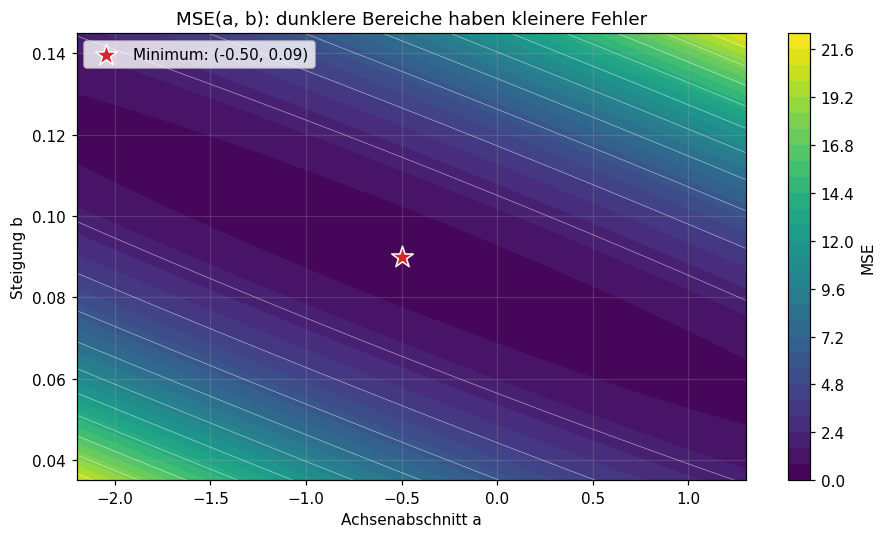

In [16]:
# Visualisierung 8: MSE als Höhenkarte für (a, b)
a_gitter = np.linspace(-2.2, 1.3, 155)
b_gitter = np.linspace(0.035, 0.145, 155)
A, B = np.meshgrid(a_gitter, b_gitter)
MSE_gitter = np.mean((y[:, None, None] - (A[None] + B[None]*x[:, None, None]))**2,
                     axis=0)

fig, ax = plt.subplots(figsize=(8.5, 5))
cont = ax.contourf(A, B, MSE_gitter, levels=30, cmap="viridis")
ax.contour(A, B, MSE_gitter, levels=10, colors="white", alpha=0.5, linewidths=0.5)
ax.scatter([a], [b], marker="*", s=220, color="tab:red", edgecolor="white",
           label=f"Minimum: ({a:.2f}, {b:.2f})", zorder=4)
ax.set(xlabel="Achsenabschnitt a", ylabel="Steigung b",
       title="MSE(a, b): dunklere Bereiche haben kleinere Fehler")
fig.colorbar(cont, ax=ax, label="MSE")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Gradient Descent in 1D (A3)

Das Ausgangsnotebook verwendet für die MSE-Funktion genau diese beiden Ableitungen:

$$\frac{\partial\mathrm{MSE}}{\partial a}=-\frac2n\sum_i\big(y_i-(a+bx_i)\big),\qquad
\frac{\partial\mathrm{MSE}}{\partial b}=-\frac2n\sum_i x_i\big(y_i-(a+bx_i)\big).$$

In jedem Schritt bewegen wir die Parameter **entgegen dem Gradienten**:

$$a_{t+1}=a_t-\eta\frac{\partial\mathrm{MSE}}{\partial a},\qquad
b_{t+1}=b_t-\eta\frac{\partial\mathrm{MSE}}{\partial b},$$

wobei $\eta$ die Lernrate ist.

**Korrektur gegenüber dem Original:** Die Eingabewerte von $x$ sind mit 30–70 relativ groß. Die alte Kombination `lr=1e-3` und unskaliertem $x$ führt zu übergroßen Schritten und `NaN`. Deshalb standardisieren wir **hier nur die Eingabe $x$**, führen Gradient Descent auf dieser Skala aus und rechnen die Parameter anschließend zurück.

In [17]:
# Dieselben partiellen Ableitungen wie im Ausgangsskript

def grad_mse_1d(a, b, x, y):
    n = x.shape[0]
    y_pred = a + b * x
    da = (-2.0 / n) * np.sum(y - y_pred)
    db = (-2.0 / n) * np.sum(x * (y - y_pred))
    return da, db


def fit_gd_1d(x, y, a0=0.0, b0=0.0, lr=0.1, steps=120, return_history=False):
    """Gradient Descent für ŷ=a+bx; optional mit Parameter- und MSE-Verlauf."""
    a_g, b_g = float(a0), float(b0)
    verlauf = [(a_g, b_g, mse(y, a_g + b_g*x))]
    for _ in range(steps):
        da, db = grad_mse_1d(a_g, b_g, x, y)
        a_g -= lr * da
        b_g -= lr * db
        verlauf.append((a_g, b_g, mse(y, a_g + b_g*x)))
    if return_history:
        return a_g, b_g, np.asarray(verlauf)
    return a_g, b_g

In [18]:
# Gradient Descent auf z-standardisiertem x; y bleibt unverändert.
x_gd, x_mu_gd, x_sd_gd = standardize(x)
a_z_gd, b_z_gd, gd_verlauf = fit_gd_1d(
    x_gd, y, a0=0.0, b0=0.0, lr=0.10, steps=120, return_history=True
)

# Umrechnung von ŷ=a_z+b_z·[(x-μ_x)/σ_x] auf ŷ=a+b·x:
b_gd = b_z_gd / x_sd_gd
a_gd = a_z_gd - b_z_gd * x_mu_gd / x_sd_gd

print(f"Formel:            a={a:+.6f}, b={b:.6f}, MSE={mse(y, y_hat):.6f}")
print(f"Gradient Descent:  a={a_gd:+.6f}, b={b_gd:.6f}, "
      f"MSE={mse(y, a_gd+b_gd*x):.6f}")
print(f"Erster MSE: {gd_verlauf[0,2]:.3f} | Letzter MSE: {gd_verlauf[-1,2]:.3f}")
assert np.allclose([a_gd, b_gd], [a, b], atol=1e-6)
assert np.isfinite(gd_verlauf).all()

Formel:            a=-0.500000, b=0.090000, MSE=0.380000
Gradient Descent:  a=-0.500000, b=0.090000, MSE=0.380000
Erster MSE: 18.000 | Letzter MSE: 0.380


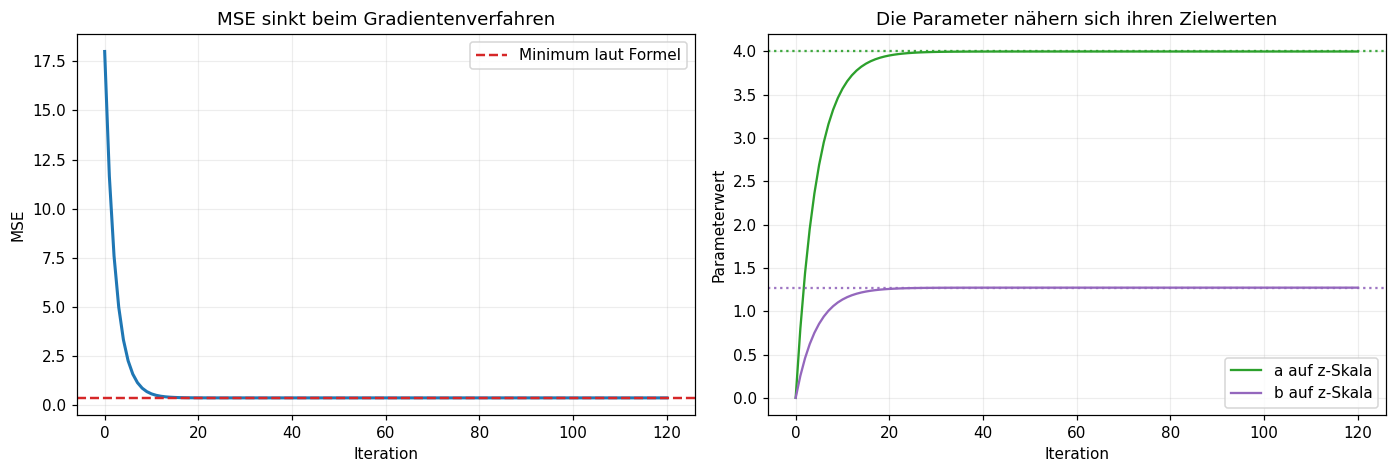

In [19]:
# Visualisierung 9: Lernkurve und Annäherung der Koeffizienten
fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.4))
iteration = np.arange(gd_verlauf.shape[0])
axes[0].plot(iteration, gd_verlauf[:, 2], color="tab:blue", lw=2)
axes[0].axhline(mse(y, y_hat), color="tab:red", ls="--", lw=1.6,
                label="Minimum laut Formel")
axes[0].set(xlabel="Iteration", ylabel="MSE", title="MSE sinkt beim Gradientenverfahren")
axes[0].legend()
axes[1].plot(iteration, gd_verlauf[:, 0], color="tab:green", label="a auf z-Skala")
axes[1].plot(iteration, gd_verlauf[:, 1], color="tab:purple", label="b auf z-Skala")
axes[1].axhline(yb, color="tab:green", ls=":", alpha=0.9)
axes[1].axhline(b*x_sd_gd, color="tab:purple", ls=":", alpha=0.9)
axes[1].set(xlabel="Iteration", ylabel="Parameterwert", title="Die Parameter nähern sich ihren Zielwerten")
axes[1].legend()
plt.tight_layout()
plt.show()

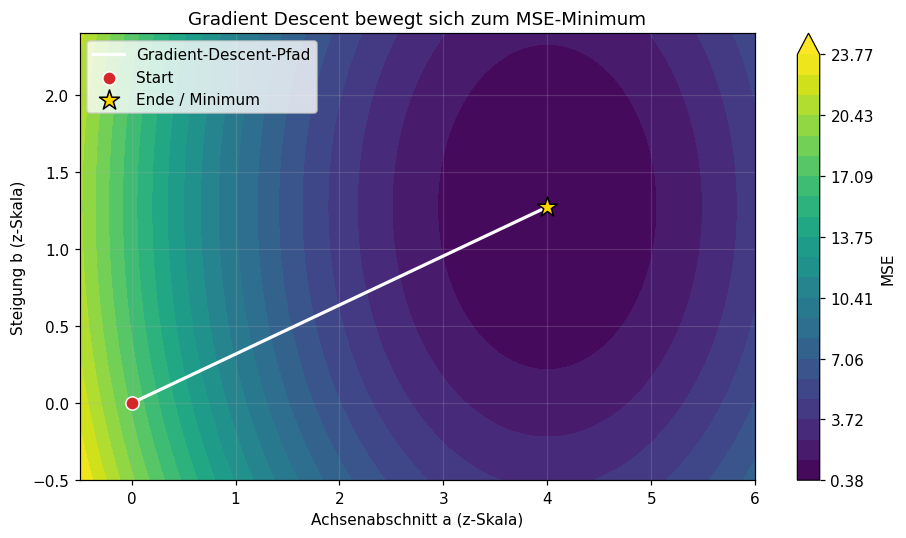

In [20]:
# Visualisierung 10: Der Weg der (standardisierten) Parameter durch die MSE-Fläche
az = np.linspace(-0.5, 6, 170)
bz = np.linspace(-0.5, 2.4, 140)
AZ, BZ = np.meshgrid(az, bz)
loss_z = np.mean((y[:,None,None] - (AZ[None]+BZ[None]*x_gd[:,None,None]))**2,
                 axis=0)

fig, ax = plt.subplots(figsize=(8.6, 5))
levels = np.linspace(loss_z.min(), min(24, loss_z.max()), 22)
cf = ax.contourf(AZ, BZ, loss_z, levels=levels, cmap="viridis", extend="max")
ax.plot(gd_verlauf[:, 0], gd_verlauf[:, 1], color="white", lw=2.1,
        label="Gradient-Descent-Pfad")
ax.scatter(gd_verlauf[0, 0], gd_verlauf[0, 1], color="tab:red", s=75,
           edgecolor="white", zorder=4, label="Start")
ax.scatter(gd_verlauf[-1, 0], gd_verlauf[-1, 1], marker="*", color="gold",
           s=190, edgecolor="black", zorder=4, label="Ende / Minimum")
ax.set(xlabel="Achsenabschnitt a (z-Skala)", ylabel="Steigung b (z-Skala)",
       title="Gradient Descent bewegt sich zum MSE-Minimum")
ax.legend(loc="upper left")
fig.colorbar(cf, ax=ax, label="MSE")
plt.tight_layout()
plt.show()

### Weiteres GD-Beispiel: Gleiche Daten, unterschiedliche Lernraten

Die Ableitungen bleiben unverändert. Wir vergleichen lediglich die Schrittgröße $\eta$ auf derselben standardisierten Eingabe – also weiterhin **nur Gradient Descent in 1D**. Große und kleine Lernraten können zu unterschiedlich schneller Annäherung führen.

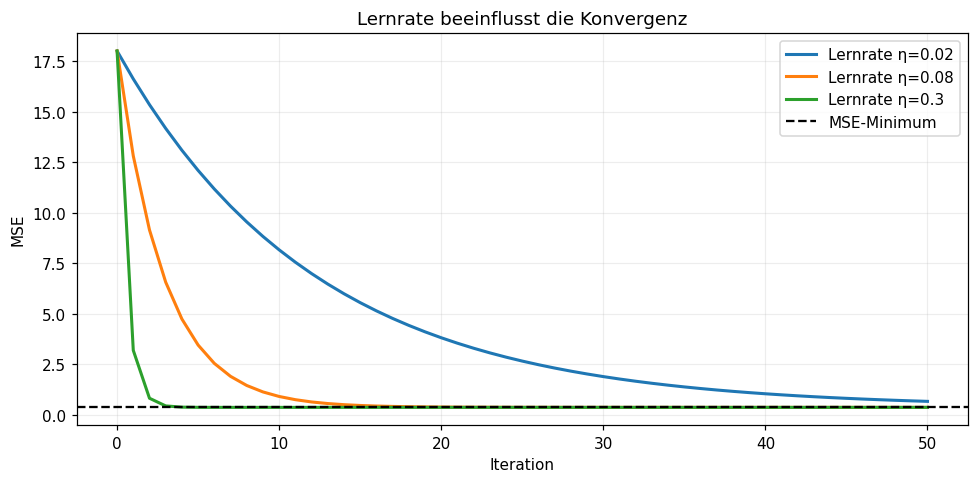

In [21]:
# Visualisierung 11: MSE-Verläufe für verschiedene stabile Lernraten
fig, ax = plt.subplots(figsize=(9, 4.5))
for lernrate in [0.02, 0.08, 0.30]:
    _, _, hist = fit_gd_1d(x_gd, y, lr=lernrate, steps=50, return_history=True)
    ax.plot(np.arange(len(hist)), hist[:, 2], lw=2, label=f"Lernrate η={lernrate}")
ax.axhline(mse(y, y_hat), color="black", ls="--", label="MSE-Minimum")
ax.set(xlabel="Iteration", ylabel="MSE", title="Lernrate beeinflusst die Konvergenz")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Mehrere Merkmale: Designmatrix + Least Squares

Im Original werden **zwei Merkmale** $x_1,x_2$ verwendet. Das lineare Modell ist:

$$\hat y = a+w_1x_1+w_2x_2.$$

Die **Designmatrix** enthält zu Beginn eine Eins-Spalte für den Achsenabschnitt $a$. Mit NumPy `np.linalg.lstsq` ermitteln wir direkt die Parameter, die die Summe der quadrierten Fehler (und damit den MSE) minimieren. Wie im Original besprechen wir **keine weiteren Details der linearen Algebra**.

In [22]:
# Datenerzeugung aus dem Original (gleicher Seed und dieselben Parameter)
rng = np.random.default_rng(0)
n, d = 120, 2
X_feats = rng.normal(size=(n, d))
w_true = np.array([2.0, -3.0])
bias_true = 1.5
noise = rng.normal(0, 0.8, size=n)
y_multi = bias_true + X_feats @ w_true + noise

# Designmatrix: erste Spalte = 1, danach x1 und x2
X_design = np.c_[np.ones(n), X_feats]
w_hat, *_ = np.linalg.lstsq(X_design, y_multi, rcond=None)
y_hat_multi = X_design @ w_hat
mse_multi = mse(y_multi, y_hat_multi)

print("X_feats-Form:  ", X_feats.shape)
print("X_design-Form: ", X_design.shape)
print("Erste drei Designmatrix-Zeilen:\n", np.round(X_design[:3], 3))
print("Wahre Parameter [a, w1, w2]:   ", [bias_true, *w_true])
print("Geschätzte Parameter:          ", np.round(w_hat, 3))
print("MSE (alle 120 Beobachtungen):   ", round(mse_multi, 3))
assert X_design.shape == (120, 3)

X_feats-Form:   (120, 2)
X_design-Form:  (120, 3)
Erste drei Designmatrix-Zeilen:
 [[ 1.     0.126 -0.132]
 [ 1.     0.64   0.105]
 [ 1.    -0.536  0.362]]
Wahre Parameter [a, w1, w2]:    [1.5, np.float64(2.0), np.float64(-3.0)]
Geschätzte Parameter:           [ 1.469  1.992 -3.12 ]
MSE (alle 120 Beobachtungen):    0.632


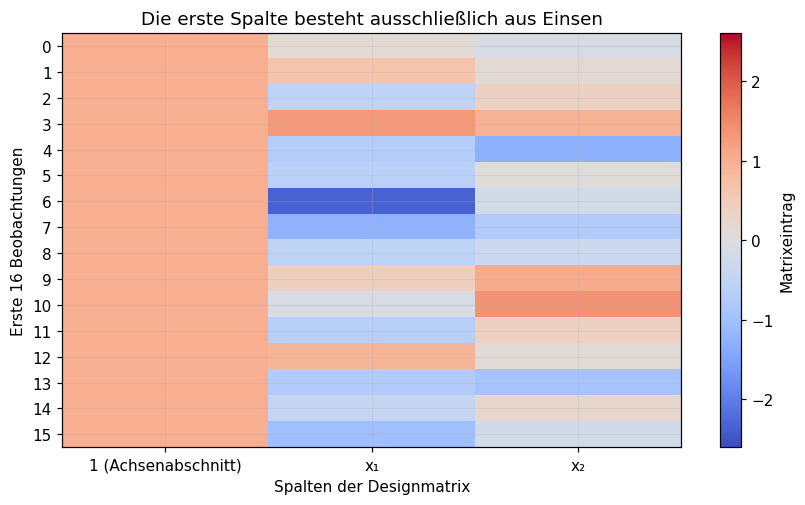

In [23]:
# Visualisierung 12: Aufbau der Designmatrix
fig, ax = plt.subplots(figsize=(7.8, 4.7))
im = ax.imshow(X_design[:16], cmap="coolwarm", aspect="auto", vmin=-2.6, vmax=2.6)
ax.set(xticks=[0, 1, 2], xticklabels=["1 (Achsenabschnitt)", "x₁", "x₂"],
       xlabel="Spalten der Designmatrix", ylabel="Erste 16 Beobachtungen",
       title="Die erste Spalte besteht ausschließlich aus Einsen")
ax.set_yticks(np.arange(16))
fig.colorbar(im, ax=ax, label="Matrixeintrag")
plt.tight_layout()
plt.show()

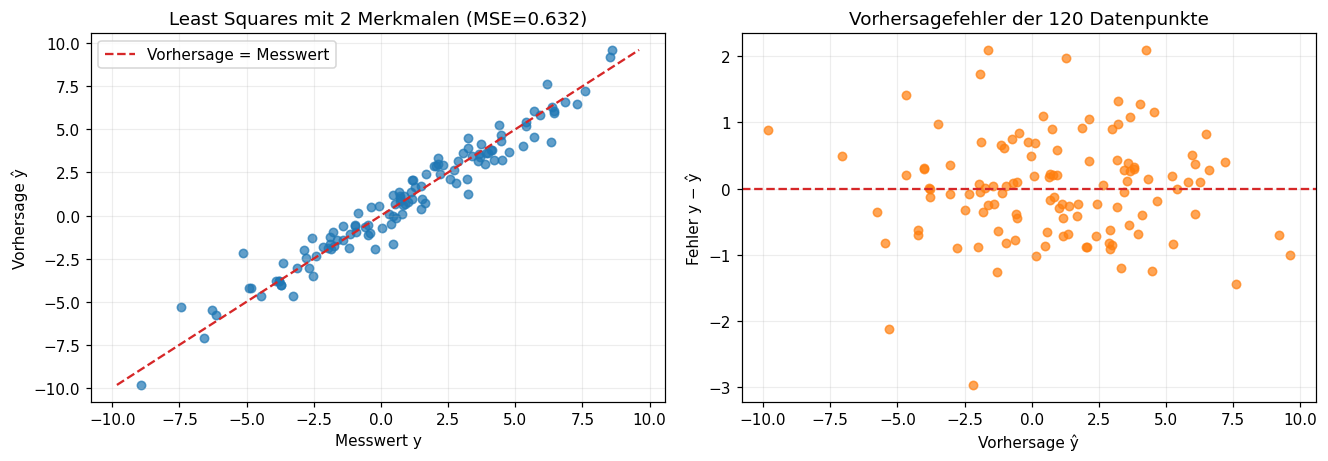

In [24]:
# Visualisierung 13: Was sagt die Mehr-Merkmal-Regression voraus?
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.3))
axes[0].scatter(y_multi, y_hat_multi, color="tab:blue", alpha=0.7, s=30)
grenze_min = min(y_multi.min(), y_hat_multi.min())
grenze_max = max(y_multi.max(), y_hat_multi.max())
axes[0].plot([grenze_min, grenze_max], [grenze_min, grenze_max],
             color="tab:red", ls="--", label="Vorhersage = Messwert")
axes[0].set(xlabel="Messwert y", ylabel="Vorhersage ŷ",
            title=f"Least Squares mit 2 Merkmalen (MSE={mse_multi:.3f})")
axes[0].legend()
reste_multi = y_multi - y_hat_multi
axes[1].scatter(y_hat_multi, reste_multi, color="tab:orange", alpha=0.7, s=30)
axes[1].axhline(0, color="tab:red", ls="--")
axes[1].set(xlabel="Vorhersage ŷ", ylabel="Fehler y − ŷ",
            title="Vorhersagefehler der 120 Datenpunkte")
plt.tight_layout()
plt.show()

### Die beiden Merkmale separat betrachten

Der Solver schätzt **beide Koeffizienten gleichzeitig**. Um eine Gerade für ein Merkmal zu zeichnen, halten wir im Plot das jeweils andere Merkmal auf **0**. Die Punkte selbst enthalten weiterhin beide Merkmale; sie müssen deshalb nicht direkt auf der eingezeichneten Geraden liegen.

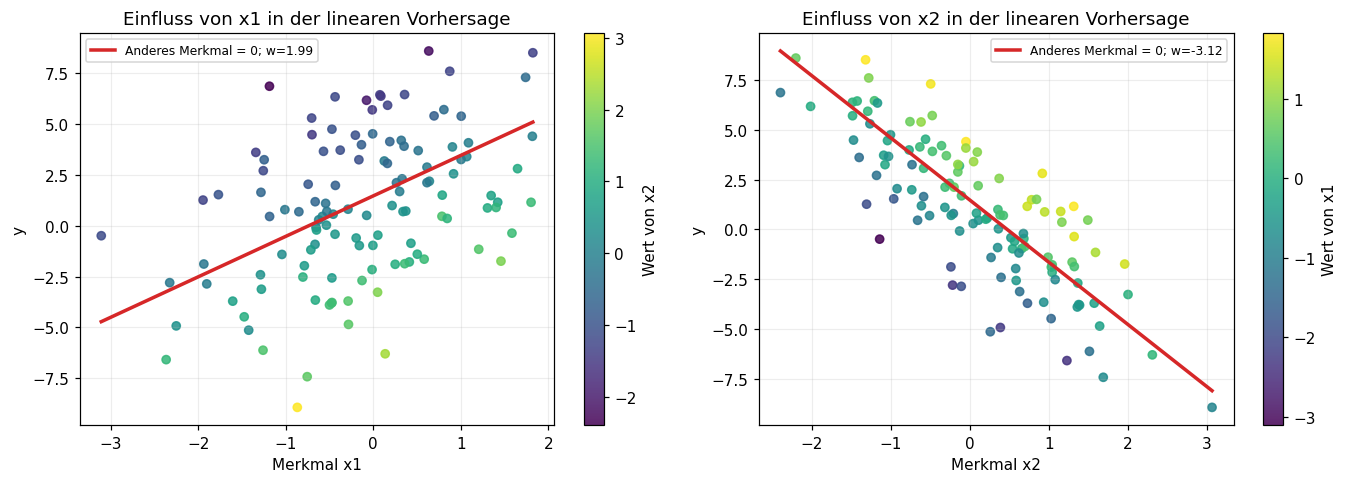

In [25]:
# Visualisierung 14: Vorhersage über x1 bzw. x2 (jeweils anderes Merkmal = 0)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
for j, ax in enumerate(axes):
    anders = 1 - j
    sc = ax.scatter(X_feats[:, j], y_multi, c=X_feats[:, anders],
                    cmap="viridis", s=29, alpha=0.85)
    werte_j = np.linspace(X_feats[:, j].min(), X_feats[:, j].max(), 120)
    ax.plot(werte_j, w_hat[0] + w_hat[j + 1] * werte_j,
            color="tab:red", lw=2.3, label=f"Anderes Merkmal = 0; w={w_hat[j+1]:.2f}")
    ax.set(xlabel=f"Merkmal x{j+1}", ylabel="y",
           title=f"Einfluss von x{j+1} in der linearen Vorhersage")
    ax.legend(fontsize=8, loc="best")
    fig.colorbar(sc, ax=ax, label=f"Wert von x{anders+1}")
plt.tight_layout()
plt.show()

## 5. Train/Test-Aufteilung und Standardisierung (A6)

Das Original teilt die **120 Beobachtungen zufällig in 75 % Training und 25 % Test**. Diesen Ablauf behalten wir bei:

1. Zufällig aufteilen.
2. Für **jede Merkmalsspalte** Mittelwert $\mu$ und Standardabweichung $\sigma$ **nur auf Train** ermitteln.
3. **Dieselben** $\mu$ und $\sigma$ auf Train **und** Test anwenden.
4. Die Parameter mit den Trainingsdaten schätzen und anschließend den **Train-MSE** und **Test-MSE** separat berechnen.

**Warum Schritt 2?** Testwerte sollen die Skalierung des trainierten Modells nicht vorab beeinflussen.

In [26]:
# Gleicher Train/Test-Prozess wie im Originalskript (75 % / 25 %)
perm = rng.permutation(n)
n_train = int(0.75 * n)
idx_tr, idx_te = perm[:n_train], perm[n_train:]
X_tr, X_te = X_feats[idx_tr], X_feats[idx_te]
y_tr, y_te = y_multi[idx_tr], y_multi[idx_te]

# Mittelwert und Streuung nur aus Trainingsdaten (spaltenweise)
mu = X_tr.mean(axis=0)
sd = X_tr.std(axis=0)
sd_safe = np.where(sd > 0, sd, 1.0)
X_tr_std = (X_tr - mu) / sd_safe
X_te_std = (X_te - mu) / sd_safe

Xtr = np.c_[np.ones(X_tr_std.shape[0]), X_tr_std]
Xte = np.c_[np.ones(X_te_std.shape[0]), X_te_std]
w_tr, *_ = np.linalg.lstsq(Xtr, y_tr, rcond=None)
y_pred_tr = Xtr @ w_tr
y_pred_te = Xte @ w_tr
mse_tr = mse(y_tr, y_pred_tr)
mse_te = mse(y_te, y_pred_te)

print(f"Train: {len(y_tr)} Beobachtungen | Test: {len(y_te)} Beobachtungen")
print("μ aus Train:", np.round(mu, 3), "| σ aus Train:", np.round(sd, 3))
print("Train-Mittelwerte nach Standardisierung:", np.round(X_tr_std.mean(axis=0), 3))
print("Train-Standardabweichungen danach:     ", np.round(X_tr_std.std(axis=0), 3))
print("Test-Mittelwerte nach Standardisierung: ", np.round(X_te_std.mean(axis=0), 3))
print("Train-MSE:", round(mse_tr, 3), "| Test-MSE:", round(mse_te, 3))
assert len(y_tr) == 90 and len(y_te) == 30
assert np.allclose(X_tr_std.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_tr_std.std(axis=0), 1, atol=1e-12)

Train: 90 Beobachtungen | Test: 30 Beobachtungen
μ aus Train: [-0.042  0.086] | σ aus Train: [1.007 1.04 ]
Train-Mittelwerte nach Standardisierung: [-0.  0.]
Train-Standardabweichungen danach:      [1. 1.]
Test-Mittelwerte nach Standardisierung:  [-0.394  0.039]
Train-MSE: 0.554 | Test-MSE: 0.915


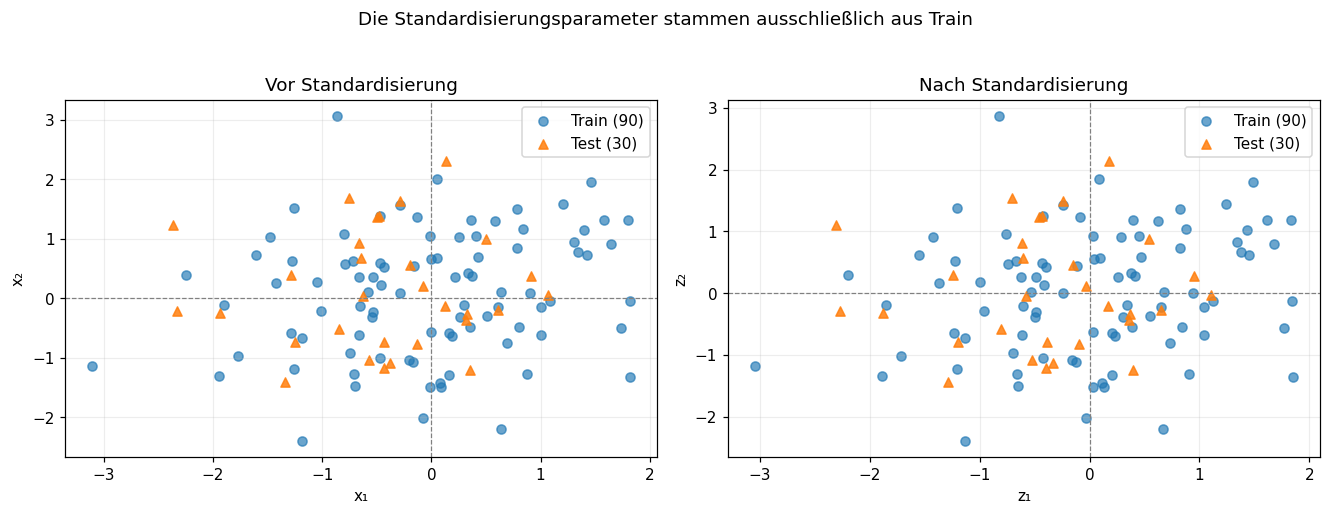

In [27]:
# Visualisierung 15: Train- und Testdaten vor/nach derselben Transformation
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.5))
for ax, tr, te, titel, xlabel, ylabel in [
    (axes[0], X_tr, X_te, "Vor Standardisierung", "x₁", "x₂"),
    (axes[1], X_tr_std, X_te_std, "Nach Standardisierung", "z₁", "z₂"),
]:
    ax.scatter(tr[:, 0], tr[:, 1], color="tab:blue", alpha=0.66,
               label=f"Train ({len(tr)})")
    ax.scatter(te[:, 0], te[:, 1], color="tab:orange", alpha=0.85,
               marker="^", label=f"Test ({len(te)})")
    ax.axhline(0, color="gray", ls="--", lw=0.8)
    ax.axvline(0, color="gray", ls="--", lw=0.8)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=titel)
    ax.legend()
fig.suptitle("Die Standardisierungsparameter stammen ausschließlich aus Train", y=1.03)
plt.tight_layout()
plt.show()

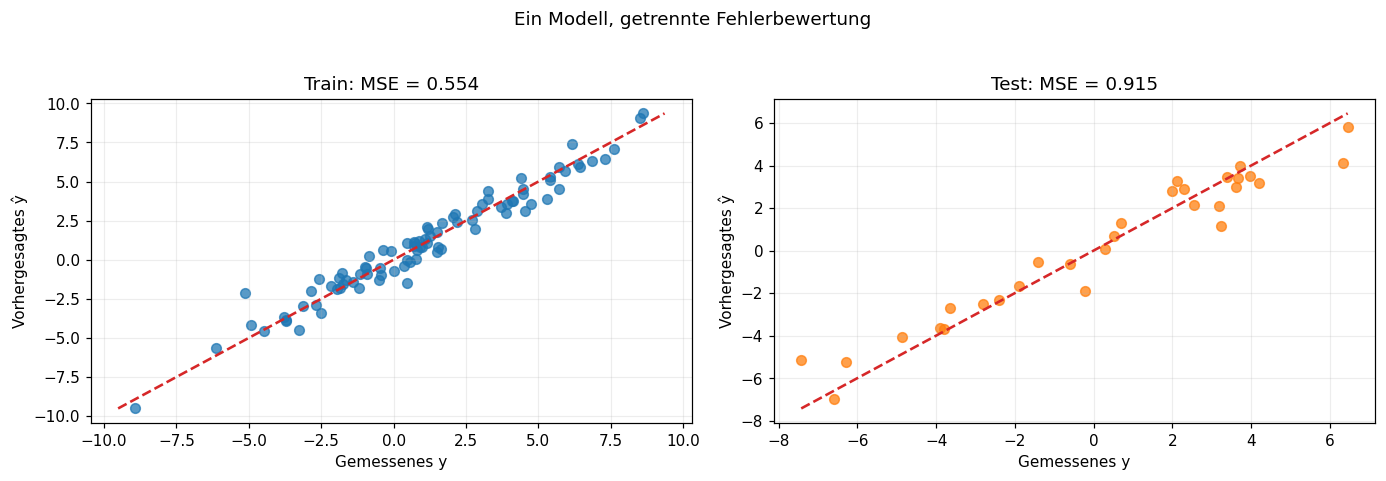

In [28]:
# Visualisierung 16: Train- und Testvorhersagen mit demselben Modell
fig, axes = plt.subplots(1, 2, figsize=(12.7, 4.2))
for ax, yt, yp, gruppe, farbe, wert in [
    (axes[0], y_tr, y_pred_tr, "Train", "tab:blue", mse_tr),
    (axes[1], y_te, y_pred_te, "Test", "tab:orange", mse_te),
]:
    ax.scatter(yt, yp, alpha=0.74, color=farbe, s=40)
    lo, hi = min(yt.min(), yp.min()), max(yt.max(), yp.max())
    ax.plot([lo, hi], [lo, hi], color="tab:red", lw=1.7, ls="--")
    ax.set(xlabel="Gemessenes y", ylabel="Vorhergesagtes ŷ",
           title=f"{gruppe}: MSE = {wert:.3f}")
fig.suptitle("Ein Modell, getrennte Fehlerbewertung", y=1.03)
plt.tight_layout()
plt.show()

## 6. Korrelationsmatrix der Merkmale (A1)

Der letzte Codeblock des Originals berechnet die **paarweisen Korrelationen der Merkmalsspalten**. Hier verwenden wir dieselbe Rechnung und machen das Resultat als Matrix sichtbar. Die Diagonale enthält jeweils $\operatorname{Corr}(x_j,x_j)=1$, solange die entsprechende Spalte nicht konstant ist.

In [29]:
def corr_matrix_cols(M):
    """Korrelationsmatrix der d Spalten einer Matrix (n,d)."""
    d = M.shape[1]
    R = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            R[i, j] = corr_xy(M[:, i], M[:, j])
    return R

R = corr_matrix_cols(X_feats)
print("Korrelationsmatrix der zwei Merkmale:\n", np.round(R, 3))
assert np.allclose(R, R.T)
assert np.allclose(np.diag(R), 1.0)

Korrelationsmatrix der zwei Merkmale:
 [[1.    0.147]
 [0.147 1.   ]]


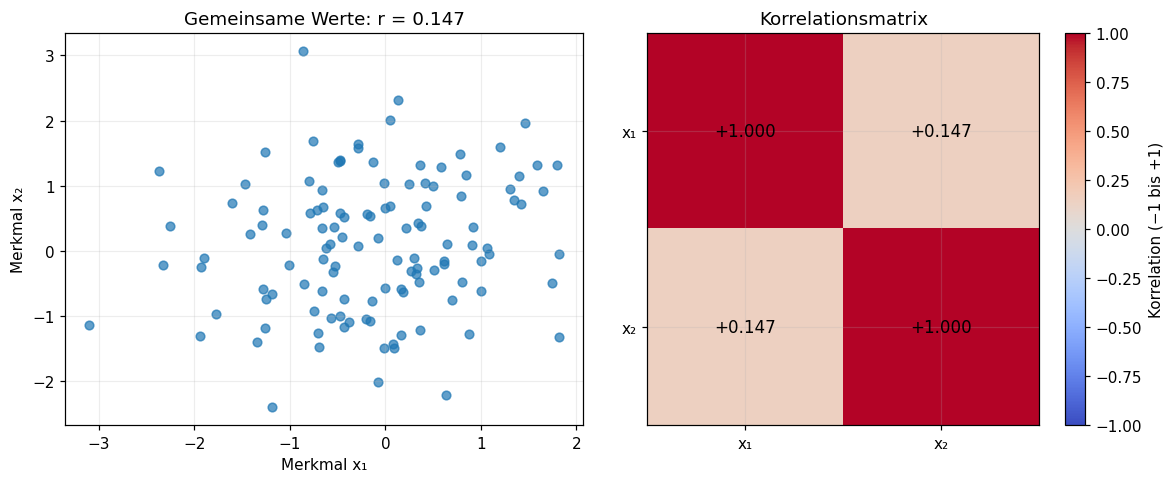

In [30]:
# Visualisierung 17: Punktwolke x1 gegen x2 + ihre Korrelationsmatrix
fig, axes = plt.subplots(1, 2, figsize=(10.9, 4.5))
axes[0].scatter(X_feats[:, 0], X_feats[:, 1], s=32,
                color="tab:blue", alpha=0.7)
axes[0].set(xlabel="Merkmal x₁", ylabel="Merkmal x₂",
            title=f"Gemeinsame Werte: r = {R[0,1]:.3f}")
image = axes[1].imshow(R, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set(xticks=[0, 1], yticks=[0, 1],
            xticklabels=["x₁", "x₂"], yticklabels=["x₁", "x₂"],
            title="Korrelationsmatrix")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{R[i,j]:+.3f}", ha="center", va="center",
                     fontsize=11, color="black")
fig.colorbar(image, ax=axes[1], label="Korrelation (−1 bis +1)")
plt.tight_layout()
plt.show()

## Zusammenfassung und ausführbare Kontrollen

Die Definitionen und Daten des Originals wurden beibehalten. Die zusätzlichen Diagramme zeigen, **wie** Mittelwert, Korrelation, Regressionsgerade, MSE-Minimum, Gradient Descent, Designmatrix und Train/Test-Auswertung zusammenhängen.

**Zum eigenen Experimentieren innerhalb derselben Themen:**

- Ändere im ersten Beispiel einen Wert in `werte` und beobachte Mittelwert, Varianz und Abweichungsdiagramm.
- Ändere einen Punkt in `y` und vergleiche erneut Regressionsgerade, MSE-Kurve und Gradientenverfahren.
- Variiere die Lernrate `lr` nach der Standardisierung und vergleiche den Verlauf des MSE.
- Verändere beim **gleichen** Train/Test-Split die beiden Merkmalsspalten und prüfe die Korrelationsmatrix sowie den Test-MSE.

Die abschließenden Tests sind auf die **ursprünglich vorgegebenen Beispielwerte** abgestimmt; nach eigenen Datenänderungen müssen ihre erwarteten Zahlen gegebenenfalls angepasst werden.

In [31]:
# Abschluss: die zentralen Resultate des Originals, ergänzt durch Konsistenzchecks
assert np.isclose(mse(y, a + b*x), 0.38)
assert np.isclose(mse(y, a_gd + b_gd*x), mse(y, a + b*x), atol=1e-8)
assert np.all(np.isfinite(w_hat))
assert np.isfinite(mse_tr) and np.isfinite(mse_te)
assert np.allclose(R, corr_matrix_cols(X_feats))

print("✓ Mittelwert/Varianz/Kovarianz/Korrelation verfügbar")
print("✓ 1D-Regressionsparameter und MSE korrekt")
print("✓ Gradient Descent liefert endliche Werte und erreicht das MSE-Minimum")
print("✓ Mehr-Merkmal-Regression mit Designmatrix berechnet")
print("✓ Train/Test-MSE nach Standardisierung berechnet")
print("✓ Korrelationsmatrix kontrolliert")

✓ Mittelwert/Varianz/Kovarianz/Korrelation verfügbar
✓ 1D-Regressionsparameter und MSE korrekt
✓ Gradient Descent liefert endliche Werte und erreicht das MSE-Minimum
✓ Mehr-Merkmal-Regression mit Designmatrix berechnet
✓ Train/Test-MSE nach Standardisierung berechnet
✓ Korrelationsmatrix kontrolliert
